# Vocabulary Fix and Clean Re-encoding

The EDA in notebook (eda_encoding) revealed a vocabulary anomaly. The raw vocabulary contained 1,048,575 distinct entries, which is impossible for real x86 execution. This notebook investigates the root cause, fixes the vocabulary using an opcode whitelist, and re-encodes all 260 trace files with the clean vocabulary in `int16`.

The raw trace files are never modified, will kept as it is. The fix is applied during the encoding pass, so the original data stays untouched and the real execution sequence is preserved.

## Setup the imports and paths

In [1]:
import sys
import os
import time
import re
import numpy as np
import pandas as pd

sys.path.append("..")

from utils import (
    encode_trace_to_npy,
    save_vocab,
    load_vocab,
    check_vocab_size,
    decode_trace_npy,
    load_encoded_trace,
    stream_opcodes,
)
from x86_opcode_whitelist import X86_OPCODE_WHITELIST

In [2]:
RAW_TRACES_DIR = "../sandbox/data/raw_traces"
FREQ_CSV = "../sandbox/data/processed_outputs/global_opcode_freq.csv"
OLD_VOCAB_JSON = "../sandbox/data/vocab.json"
CLEAN_VOCAB_JSON = "../sandbox/data/vocab_clean.json"
ENCODED_DIR = "../sandbox/data/encoded_traces"

# Load the frequency table and vocab saved in previous notebook
df_freq = pd.read_csv(FREQ_CSV)
old_vocab = load_vocab(OLD_VOCAB_JSON)

print(f"Frequency Table Entries: {len(df_freq):,}")
print(f"Old Vocab Entries: {len(old_vocab):,}")
print(f"Total Opcode Instances: {df_freq.total_count.sum():,}")

Frequency Table Entries: 1,340,177
Old Vocab Entries: 147,464
Total Opcode Instances: 53,420,966,042


----
## Root Cause Investigation

### The anomaly

The raw vocabulary size of 1,048,575 entries cannot represent real x86 execution. The full x86/x64 instruction set defines only a few thousand mnemonics and a typical JVM execution uses only a few hundred of them. Inspection of the vocabulary shows entries like `MOVMOV`, `OV`, `MP` and `AADDCALL_NEAR` - fragments and concatenations of real opcode names.

### Root Cause - Confirmed from the opcode_tracer.cpp code file

The tracer (`opcode_tracer.cpp`) logs each executed instruction using this function:

```cpp
VOID LogOpcode(UINT32 opcode)
{
    outFile << OPCODE_StringShort(opcode) << "\n";
    opcodeCount++;
}
```

`LogOpcode` is registered through `INS_InsertCall` and runs once per executed instruction. The JVM is heavily multi-threaded (for example - application threads, JIT compiler threads, GC threads), and PIN instruments all of them. `std::ofstream` is not thread safe for multi character writes, so when two threads call `LogOpcode` at the same moment their output interleaves at the byte level inside the write buffer. The tail of one opcode string collides with the next which producing these corrupted lines.

The evidence of this issue is in the data matches:

- `MOVMOV` appears 3,996,996 times - the race fires reliably for the most common opcode pair
- `OV`, `MP`, `USH`, `EST` - partial tail writes of MOV, CMP, PUSH, TEST
- Every corrupted string is a fragment or concatenation of real opcode names

### Why regex splitting cannot work

At first, a corrupted string looks recoverable. `MOVMOV` could be split back into MOV + MOV, and a whitelist of real opcodes could be used to find the split points. However, this does not work for two reasons.

1. The first reason is ambiguity (random). A string like `AADDCALL_NEAR` has an arbitrary interleave position, the `A` prefix is the tail byte of a different opcode written by another thread. The boundary is not recoverable, so splitting would invent instructions that were never executed.

2. The second and more important reason is specific to this project, which uses N-grams as the feature representation. An N-gram captures the adjacency between opcodes, that is which opcode follows which. A single corrupted line such as `MOVMOV` can shows in three different ways that cannot be told apart from the corrupted text alone.

- Two real sequential MOV instructions whose newline characters were lost in the race. Here the split would be correct.
- Two MOV instructions written by two different threads that interleaved. Here both instructions are real, but they were not next to each other in the sequence (fabricated N-gram). they never happened one right after the other in either thread.
- A `MOVZX` operation started but was cut off after the `MOV` instruction. Another thread then completed it with a `MOV` command. In this case one of the two commands is entirely made up.

In the second case the regex splitting would produce a MOV to MOV transition that never happened in either thread's execution. Since the model learns from exactly these transitions, regex recovery risks injecting fabricated N-gram edges into the feature space the classifier will depends on. Discarding the corrupted line avoids this completely and one transition is lost rather than a wrong one being invented. And this is best data cleaning practice on **ML Development Cycle - it is better to lose a small amount of data than to introduce noise that will mislead the model.**

### References
- *Intel Corporation, Pin: A Dynamic Binary Instrumentation Tool - `OPCODE_StringShort()` and instrumentation threading model*
- *Intel Corporation (2024) Intel 64 and IA-32 Architectures Software Developer's Manual, Vol 2 - authoritative x86/x64 instruction reference*
- *ISO/IEC 14882:2020 - `std::ofstream` thread safety requirements*


### Data loss from removing the corrupted opcodes - TBA at Later

### Frequency distribution of the corruption

Looking at the frequency distribution to see the scale of the problem and why a simple frequency threshold cannot solve this.

In [3]:
# Count how many vocab entries survive at each frequency threshold
print("Vocab entries surviving each minimum count threshold:")
for threshold in [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]:
    n = (df_freq.total_count >= threshold).sum()
    print(f"{threshold:>10,} -> {n:>9,} entries")

print("\nReal x86 execution uses only a few hundred distinct opcodes")
print("so even the strictest threshold above could keep corrupted entries.")

Vocab entries surviving each minimum count threshold:
         1 -> 1,340,177 entries
        10 ->   147,464 entries
       100 ->    32,129 entries
     1,000 ->     7,208 entries
    10,000 ->     1,432 entries
   100,000 ->       293 entries
 1,000,000 ->       128 entries

Real x86 execution uses only a few hundred distinct opcodes
so even the strictest threshold above could keep corrupted entries.


In [4]:
# Show why frequency filtering alone fails
# These corrupted strings appear millions of times because the race condition fires reliably for the most common opcode pairs
corrupted_examples = ["MOVMOV", "OV", "MP", "MO", "V", "P", "M", "CMPMOV", "PUSHMOV"]

print("High frequency corrupted entries (all above any usable threshold):\n")

subset = df_freq[df_freq.opcode.isin(corrupted_examples)].sort_values("total_count", ascending=False)
print(subset.to_string(index=False))

print("\nA frequency threshold high enough to remove these would also remove")
print("genuinely rare real opcodes like XSAVEC or SYSCALL variants, that's not a good solution.")

High frequency corrupted entries (all above any usable threshold):

 opcode  total_count   proportion
     OV      4538803 8.496295e-05
 MOVMOV      3996996 7.482074e-05
      V      1894720 3.546772e-05
     MP      1604832 3.004124e-05
     MO      1302422 2.438035e-05
      P      1232569 2.307276e-05
      M      1011022 1.892557e-05
 CMPMOV       958179 1.793638e-05
PUSHMOV       668972 1.252265e-05
      M            3 5.615773e-11
      M            3 5.615773e-11
      M            2 3.743848e-11
      M            1 1.871924e-11
      M            1 1.871924e-11
      M            1 1.871924e-11
      M            1 1.871924e-11
      M            1 1.871924e-11
      P            1 1.871924e-11
      P            1 1.871924e-11
      M            1 1.871924e-11
      P            1 1.871924e-11
      M            1 1.871924e-11
      M            1 1.871924e-11
     MP            1 1.871924e-11

A frequency threshold high enough to remove these would also remove
genuinely rar

----
## Opcode Whitelist Filtering

The whitelist (`x86_opcode_whitelist.py` file) contains confirmed real x86/x64 opcode strings as produced by PIN's `OPCODE_StringShort()` API. It was built from the Intel Software Developer's Manual Vol 2 instruction reference and PIN's documentation.

In [5]:
print(f"Whitelist Size: {len(X86_OPCODE_WHITELIST)} opcode names")

clean_df = df_freq[df_freq.opcode.isin(X86_OPCODE_WHITELIST)]
removed_df = df_freq[~df_freq.opcode.isin(X86_OPCODE_WHITELIST)]

total = df_freq.total_count.sum()
kept = clean_df.total_count.sum()

print(f"Vocab Entries Kept: {len(clean_df):,}")
print(f"Vocab Entries Removed: {len(removed_df):,}")
print(f"Stream Kept: {kept / total * 100:.6f}%")
print(f"Stream Lost: {(total - kept) / total * 100:.6f}%")
print(f"Lost Opcode Instances: {total - kept:,}")

Whitelist Size: 469 opcode names
Vocab Entries Kept: 287
Vocab Entries Removed: 1,339,890
Stream Kept: 99.784932%
Stream Lost: 0.215068%
Lost Opcode Instances: 114,891,395


### Manual review of removed high frequency entries

Safety check before committing to the whitelist. Every removed entry above 50K occurrences is listed here, each one must be confirmable as corruption (a fragment or concatenation of real opcode names). 
**When a real opcode ever appears in this list it will be added to the whitelist and this notebook needs to be re-run.**

In [6]:
review = removed_df[removed_df.total_count >= 50_000].sort_values("total_count", ascending=False)

print(f"Removed Entries Above 50K Occurrences ({len(review)}):\n")
print(review.to_string(index=False))

Removed Entries Above 50K Occurrences (298):

      opcode  total_count   proportion
          OV      4538803 8.496295e-05
      MOVMOV      3996996 7.482074e-05
           V      1894720 3.546772e-05
          MP      1604832 3.004124e-05
          MO      1302422 2.438035e-05
           P      1232569 2.307276e-05
           M      1011022 1.892557e-05
           Z       977889 1.830534e-05
      CMPMOV       958179 1.793638e-05
      MOVCMP       957191 1.791789e-05
          OP       931936 1.744514e-05
         USH       739579 1.384436e-05
         EST       678534 1.270164e-05
     PUSHMOV       668972 1.252265e-05
          DD       656895 1.229658e-05
       JZMOV       646550 1.210293e-05
     MOVPUSH       623628 1.167384e-05
        MMOV       593347 1.110701e-05
       MOVJZ       587922 1.100545e-05
        MOVM       573060 1.072725e-05
      ADDMOV       569081 1.065277e-05
     TESTMOV       562343 1.052663e-05
      MOVPOP       543729 1.017819e-05
     MOVTEST      

### Save the clean vocabulary list

The clean vocab is the sorted version of the whitelist with the opcodes actually observed in the dataset. Sorting ensures that the ID mapping stays the same every time it executes.

In [7]:
clean_vocab = sorted(clean_df.opcode)
check_vocab_size(clean_vocab)

save_vocab(clean_vocab, CLEAN_VOCAB_JSON)

print(f"Clean Vocabulary saved to {CLEAN_VOCAB_JSON}")
print(f"{len(clean_vocab)} opcodes")
print(f"Fits int16: {len(clean_vocab) <= np.iinfo(np.int16).max}")

Clean Vocabulary saved to ../sandbox/data/vocab_clean.json
287 opcodes
Fits int16: True


----
## Clean Re-encoding with int16

Each raw trace file is streamed once and encoded with the clean vocabulary. Opcodes not in the whitelist are skipped during the pass, they were never real instructions, so removing them does not alter the program's actual execution sequence. The raw `.txt` files are not modified, the original data is preserved, and the clean encoded `.npy` files are written to a new directory.

In [8]:
# The old int32 files are deleted at this point - the entire directory is removed, creating new one
os.makedirs(ENCODED_DIR, exist_ok=True)
print("Encoded directory created")

Encoded directory created


In [9]:
trace_files = sorted([
    os.path.join(RAW_TRACES_DIR, f)
    for f in os.listdir(RAW_TRACES_DIR)
    if f.endswith(".txt")
])

encode_times = {}
encode_counts = {}
skipped = 0

vocab_to_id = {op: i for i, op in enumerate(clean_vocab)}
valid_set = set(clean_vocab)

print(f"Re-encoding {len(trace_files)} files with clean vocab JSON (int16)\n")
total_start = time.time()

# Re-encode all traces with the new clean vocab, saving as int16 numpy arrays
for i, path in enumerate(trace_files, 1):
    filename = os.path.basename(path)
    npy_name = filename.replace(".txt", ".npy")
    npy_path = os.path.join(ENCODED_DIR, npy_name)

    # Skip if already encoded as int16 from a previous run of this notebook
    if os.path.exists(npy_path):
        arr = load_encoded_trace(npy_path)
        if arr.dtype == np.int16:
            encode_counts[filename] = len(arr)
            skipped += 1
            continue
        os.remove(npy_path) # Remove the old int32 file and re-encode as int16 - safty check

    t0 = time.time()
    n = encode_trace_to_npy(path, vocab_to_id, npy_path, valid_opcodes=valid_set)
    elapsed = time.time() - t0

    encode_times[filename] = elapsed
    encode_counts[filename] = n

    if i % 10 == 0 or i == len(trace_files):
        done = time.time() - total_start
        print(f"  [{i:>3}/{len(trace_files)}]  elapsed: {done/60:.1f} min")

print(f"\nRe-encoding complete in {(time.time()-total_start)/60:.1f} min")

if skipped > 0:
    print(f"Skipped {skipped} files already encoded as int16")

Re-encoding 260 files with clean vocab JSON (int16)

  [ 10/260]  elapsed: 9.0 min
  [ 20/260]  elapsed: 16.8 min
  [ 30/260]  elapsed: 24.9 min
  [ 40/260]  elapsed: 32.8 min
  [ 50/260]  elapsed: 41.0 min
  [ 60/260]  elapsed: 49.1 min
  [ 70/260]  elapsed: 57.0 min
  [ 80/260]  elapsed: 65.6 min
  [ 90/260]  elapsed: 73.9 min
  [100/260]  elapsed: 82.2 min
  [110/260]  elapsed: 90.8 min
  [120/260]  elapsed: 99.8 min
  [130/260]  elapsed: 108.3 min
  [140/260]  elapsed: 118.0 min
  [150/260]  elapsed: 126.3 min
  [160/260]  elapsed: 133.7 min
  [170/260]  elapsed: 142.2 min
  [180/260]  elapsed: 150.7 min
  [190/260]  elapsed: 160.3 min
  [200/260]  elapsed: 169.2 min
  [210/260]  elapsed: 178.2 min
  [220/260]  elapsed: 186.3 min
  [230/260]  elapsed: 194.7 min
  [240/260]  elapsed: 202.6 min
  [250/260]  elapsed: 210.4 min
  [260/260]  elapsed: 219.0 min

Re-encoding complete in 219.0 min


### Verify the clean encoding

Three checks using a one sample file

1. The `.npy` dtype is `int16`
2. Round trip - decoded opcodes match the raw file with corrupted lines removed, in the same order
3. The dropped count matches the corruption rate

In [10]:
sample_txt = trace_files[0]
sample_name = os.path.basename(sample_txt)
sample_npy = os.path.join(ENCODED_DIR, sample_name.replace(".txt", ".npy"))

arr = load_encoded_trace(sample_npy)
print(f"Sample File: {sample_name}")
print(f"dtype: {arr.dtype}")
print(f"Encoded: {len(arr):,} opcodes")

# Round trip check - first N raw opcodes with corruption removed should equal decoded
N = 100_000
raw_clean = []

for op in stream_opcodes(sample_txt):
    if op in valid_set:
        raw_clean.append(op)
    if len(raw_clean) == N:
        break

decoded = decode_trace_npy(sample_npy, clean_vocab)[:N]

match = raw_clean == decoded
print(f"Round trip check on '{sample_name}' (First {N} opcodes): {'PASS' if match else 'FAIL'}")

# Dropped rate for this file
raw_total = sum(1 for _ in stream_opcodes(sample_txt))
dropped = raw_total - len(arr)

print(f"\nRaw Lines: {raw_total:,}")
print(f"Encoded: {len(arr):,}")
print(f"Dropped: {dropped:,} ({dropped/raw_total*100:.4f}%) - Corrupted lines removed")

Sample File: GommeHD.net-Java-API-2.2.0-jar-with-dependencies.txt
dtype: int16
Encoded: 260,119,503 opcodes
Round trip check on 'GommeHD.net-Java-API-2.2.0-jar-with-dependencies.txt' (First 100000 opcodes): PASS

Raw Lines: 260,702,272
Encoded: 260,119,503
Dropped: 582,769 (0.2235%) - Corrupted lines removed


### Storage Comparison

The `int16` encoding now showing the full storage reduction that `int32` could not deliver in the previous notebook.

In [12]:
size_rows = []

# Compare the size of the raw text files to the encoded numpy arrays
for path in trace_files:
    filename = os.path.basename(path)
    npy_path = os.path.join(ENCODED_DIR, filename.replace(".txt", ".npy"))
    txt_mb = os.path.getsize(path) / 1e6
    npy_mb = os.path.getsize(npy_path) / 1e6 if os.path.exists(npy_path) else None
    size_rows.append({"filename": filename, "txt_mb": txt_mb, "npy_mb": npy_mb})

df_sizes = pd.DataFrame(size_rows)
df_sizes["reduction"] = 1 - df_sizes["npy_mb"] / df_sizes["txt_mb"]

print("File Size Summary")
print(df_sizes[["txt_mb", "npy_mb", "reduction"]].describe().round(2))
print(f"\nTotal Raw Text: {df_sizes.txt_mb.sum()/1024:.1f} GB")
print(f"Total Encoded: {df_sizes.npy_mb.sum()/1024:.1f} GB")
print(f"Average Reduction: {df_sizes.reduction.mean()*100:.1f}%")

File Size Summary
        txt_mb  npy_mb  reduction
count   260.00  260.00     260.00
mean    911.86  410.05       0.55
std     162.25   73.25       0.00
min     592.95  266.69       0.54
25%     841.85  378.15       0.55
50%     866.78  389.37       0.55
75%    1093.42  492.86       0.55
max    1228.45  553.53       0.56

Total Raw Text: 231.5 GB
Total Encoded: 104.1 GB
Average Reduction: 55.0%


----

### Method Comparison - Streaming vs Clean Encoded Array

In [ ]:
# The streaming timings were saved in eda_encoding notebook - streaming_timing.csv
# It can be compared with this notebook's new clean encoded time data
df_stream = pd.read_csv("../sandbox/data/processed_outputs/streaming_timing.csv")
stream_times_saved = dict(zip(df_stream["filename"], df_stream["stream_sec"]))

# Build a comparison table for files where it has both timings
common = set(stream_times_saved.keys()) & set(encode_times.keys())

if common:
    rows = []

    # Compare the streaming and encoding rates for files that have both timings
    for fname in sorted(common):
        n_ops = encode_counts.get(fname, 0) # Get the number of opcodes
        s_time = stream_times_saved[fname] # Get the streaming times
        e_time = encode_times[fname] # Get the encoding time

        rows.append({
            "filename": fname,
            "opcodes": n_ops,
            "stream_sec":  round(s_time, 2),
            "encode_sec":  round(e_time, 2),
            "stream_rate": int(n_ops / s_time) if s_time > 0 else 0,
            "encode_rate": int(n_ops / e_time) if e_time > 0 else 0,
        })

    df_compare = pd.DataFrame(rows)

    print("Method Comparison - Clean int16 Encoding (Files processed in both passes):\n")
    print(f"  Streaming - AVG Rate: {df_compare['stream_rate'].mean():>10,.0f} opcodes/sec")
    print(f"  Encoding - AVG Rate: {df_compare['encode_rate'].mean():>10,.0f} opcodes/sec")
    print(f"  Encoding is around {df_compare['encode_rate'].mean()/df_compare['stream_rate'].mean():.1f}x faster than streaming")

    df_compare.to_csv("../sandbox/data/processed_outputs/method_comparison_clean.csv", index=False)
    print("\nSaved to method_comparison_clean.csv")

else:
    print("No common files between the saved stream timings and the clean encode timings.")
    print("If all files were already encoded (or skipped), rerun on a new ENCODED_DIR to get encode timings.")

Method Comparison - Clean int16 Encoding (Files processed in both passes):

  Streaming - AVG Rate:  2,614,630 opcodes/sec
  Encoding - AVG Rate:  4,063,265 opcodes/sec
  Encoding is around 1.6x faster than streaming

Saved to method_comparison_clean.csv


----
## Findings and Observations of this Notebook

This notebook fixed the vocabulary corruption identified in the EDA - Encoding step and re-encoded all 260 files with the clean vocabulary. Three main outcomes came from this process.

### 1. Vocabulary reduced to real opcodes only

The whitelist filtering reduced the vocabulary from 147,464 corrupted entries down to 287 confirmed real x86 opcode types. This is consistent with what a real JVM execution should produce, only a few hundred distinct opcodes.

### 2. Minimal data loss

Removing the corrupted opcodes removed only 0.215% of the total opcode stream, keeping 99.785% intact. Across each fles it is 114,891,395 opcodes (~115 million) removed out of 53,420,966,042 (~53.4 billion). so no file lost a meaningful portion of its behavioural pattern.

### 3. Storage and performance recovered with int16

With the clean vocabulary now fitting inside the int16 range (287 entries which are well under the 32,767 limit), the encoding switched back from int32 to int16. This recovered the storage reduction that int32 could not provided ealier notebook, the encoded files are now around half the size of the raw text again rather than only 9.9% smaller.

The clean 287 opcode vocabulary is now the fixed feature space for all the feature engineering, and next steps of this development process.

#### Visualization for Findings and Observations

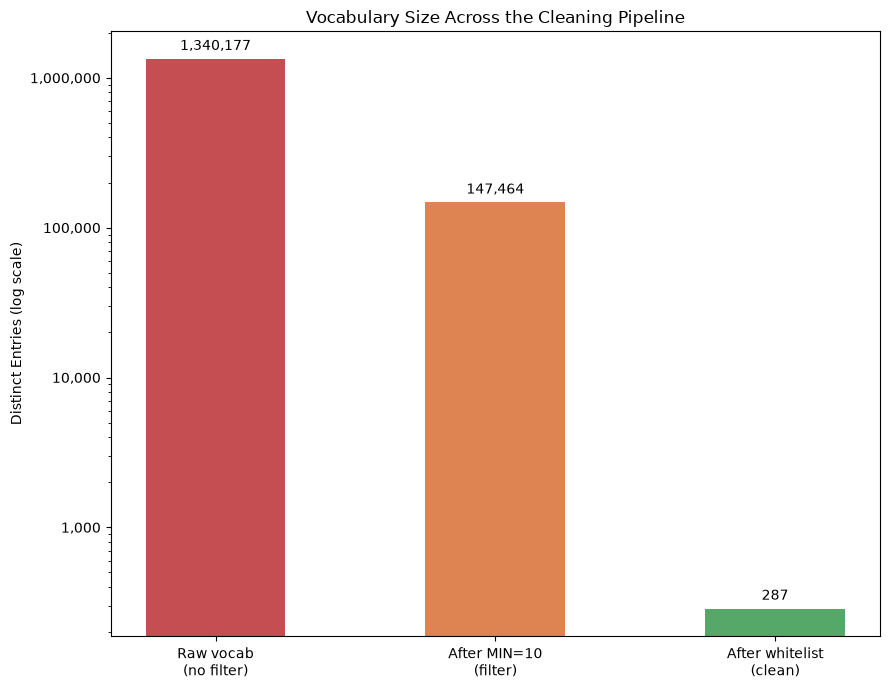

In [21]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(9, 7))

vocab_stages = ["Raw vocab\n(no filter)", "After MIN=10\n(filter)", "After whitelist\n(clean)"]
vocab_counts = [1_340_177, 147_464, 287]
colors = ["#C44E52", "#DD8452", "#55A868"]

bars = ax.bar(vocab_stages, vocab_counts, color=colors, width=0.5)
ax.set_title("Vocabulary Size Across the Cleaning Pipeline")
ax.set_ylabel("Distinct Entries (log scale)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.bar_label(bars, fmt=lambda x: f"{int(x):,}", padding=4)

plt.tight_layout()
plt.show()